In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

import os
os.environ["PATH"] = "/global/common/software/nersc9/texlive/2024/bin/x86_64-linux:" + os.environ["PATH"]

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = "Times New Roman"

import healpy as hp
import pollux
import pyccl
import scipy.stats
from tqdm.auto import trange

import pickle
import sacc

import re
import itertools


In [3]:
seed = 0
nside = 8192
sim_root = "/pscratch/sd/d/desc/HOS_Sims/"
save_dir_root = os.path.join(os.environ["CFS"], "lsst/shared/external/HACC-HOS-Y1/HOS_Sims")


In [4]:
remove_shotnoise = False

sim_configs = list(itertools.product(["HACC091_1024", "HACC150_3"], [4, 3, 2, 1]))

shotnoise_dict = {}
shotnoise_np_dict = {}

for sim_relative_path, snap_sub_every_n in sim_configs:

    dndz_flag = "SRDv1_nz"
    kappa_dir = dndz_flag if dndz_flag != "Euclid_dndz_fu08_bin1-5" else "kappa_" + dndz_flag

    reader_dict = dict(
        path=os.path.join(sim_root, sim_relative_path),
        run_params="run/indat.params",
        snap_sub_every_n=snap_sub_every_n,
    )
    reader = pollux.reader.HACCReader(**reader_dict)
    reader_halo = pollux.reader.HACCHaloReader(halo_path="analysis/Halos/b0168/Props", **reader_dict)
    cosmo = reader.cosmo

    densitymax_z = 1.5
    builder_dict = dict(
        nside=nside,
        save_dir=os.path.join(
            save_dir_root,
            sim_relative_path,
            f"shells_z{reader.nsnapshots}_subsampledensitymax{densitymax_z}_nside{nside}/",
        ),
        apply_grid_isometry=True,
        seed=seed,
        subsample_box={"densitymax_z": densitymax_z},
        group_isometries=True,
        dtype=np.float32,
        wsp_dir=save_dir_root,
    )

    shell_info_path = builder_dict["save_dir"] + f"shell_hacc_seed{seed}_shell_info.npy"
    if os.path.exists(shell_info_path):
        os.remove(shell_info_path)

    builder = pollux.shells.SnapshotShellBuilder(reader, **builder_dict)
    builder_halo = pollux.shells.SnapshotShellBuilder(reader_halo, **builder_dict)

    dndz_path = f"data/{dndz_flag}.txt" if dndz_flag == "SRDv1_nz" else f"data/{dndz_flag}.dat"
    dndz = np.loadtxt(dndz_path)

    lensing = pollux.lensing.BornLensingBuilder(
        builder,
        nzs=[(dndz[:, 0], dndz[:, i]) for i in range(1, 6)],
        kappa_dir=kappa_dir,
        wsp_dir=save_dir_root,
        sigma_e=0.3,
    )

    key = 1024 if "1024" in sim_relative_path else 2048

    if key == 2048 and snap_sub_every_n == 1:
        Cls_th = lensing.predict_cls(auto_only=False, error_bars=True, stacked=True)

    wsp = builder.get_cls_wsp()
    bpws = wsp.get_bandpower_windows()[0, :, 0, :]

    shotnoise_dict.setdefault(key, {})

    shotnoise_dict[key][builder.nshells] = {
        f"({ikappa1}, {ikappa2})": sum(
            np.dot(bpws, np.ones(bpws.shape[1])) *
            lensing.compute_weight(imap, ikappa1) *
            lensing.compute_weight(imap, ikappa2) /
            builder.get_sky_density(imap)
            for imap in range(builder.nshells)
        )
        for ikappa1, ikappa2 in itertools.product(range(lensing.nkappas), repeat=2)
    }


*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC091_1024/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x2c9ddd70e65a6e61
  - Found 101 snapshots : [ 99 103 107 111 115 119 123 127 131 135 139 143 147 151 155 159 163 167
 171 175 179 183 187 191 195 199 203 207 211 215 219 223 227 231 235 239
 243 247 251 255 259 263 267 271 275 279 283 287 291 295 299 303 307 311
 315 319 323 327 331 335 339 343 347 351 355 359 363 367 371 375 379 383
 387 391 395 399 403 407 411 415 419 423 427 431 435 439 443 447 451 455
 459 463 467 471 475 479 483 487 491 495 499]
  - Subsampling : keeping every 4 snapshots, returns 26 snapshots
*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC091_1024/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	N

[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

Loading workspace in /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/wsp_nside8192.wsp


In [5]:
N_part_a = 2048

sim_list_a = ["HACC150_3", "HACC195_2"]
nshells_list_a = [26, 34, 51, 101]
seed_list_a = [0, 1, 2, 3, 4]

path = f"subsampledensitymax{densitymax_z}"
extra_info = "method\ (1)"

Cls_dict_a = {}

for i_sim in sim_list_a:
    for i_nshells in nshells_list_a:
        for i_seed in seed_list_a:
            fits_file = os.path.join(
                os.environ["PSCRATCH"], "HOS_Sims", i_sim, 
                f"shells_z{i_nshells}_{path}_nside{nside}",
                kappa_dir, f"kappa_hacc_seed{i_seed}_nside{nside}_cls.fits"
            )
            
            if not os.path.exists(fits_file):
                print(f"File not found: {fits_file}")
                continue
            
            Cls = {}
            s = sacc.Sacc.load_fits(fits_file)
            
            for t1, t2 in s.get_tracer_combinations():
                ell, cell = np.column_stack([s.get_ell_cl("galaxy_convergence_cl", t1, t2)])
                t1_n = re.search(r'\d+', t1).group()
                t2_n = re.search(r'\d+', t2).group()
                Cls[f"({t1_n}, {t2_n})"] = np.column_stack([ell, cell])

            key = (N_part_a, i_sim, i_seed, i_nshells, extra_info)
            Cls_dict_a[key] = Cls
            print(f"Stored Cls for {key}")

if remove_shotnoise:
    for key1 in Cls_dict_a.keys():
        for key2 in Cls_dict_a[key1].keys():
            Cls_dict_a[key1][key2][:, 1] -= shotnoise_dict[key1[0]][key1[3]][f"{key2}"]


Stored Cls for (2048, 'HACC150_3', 0, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 1, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 2, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 3, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 4, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 0, 34, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 1, 34, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 2, 34, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 3, 34, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 4, 34, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 0, 51, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 1, 51, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 2, 51, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 3, 51, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 4, 51, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 0, 101, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 1, 101, 'method\\ (1)')
Stored Cls f

In [6]:
N_part_b = 1024

sim_list_b = ["HACC091_1024", "HACC106_1024"]
nshells_list_b = [26, 34, 51, 101]
seed_list_b = [0, 1, 2, 3, 4]

path = f"subsampledensitymax{densitymax_z}"
extra_info = "method\ (1)"

Cls_dict_b = {}

for i_sim in sim_list_b:
    for i_nshells in nshells_list_b:
        for i_seed in seed_list_b:
            fits_file = os.path.join(
                save_dir_root, i_sim, 
                f"shells_z{i_nshells}_{path}_nside{nside}",
                kappa_dir, f"kappa_hacc_seed{i_seed}_nside{nside}_cls.fits"
            )
            
            if not os.path.exists(fits_file):
                print(f"File not found: {fits_file}")
                continue
            
            Cls = {}
            s = sacc.Sacc.load_fits(fits_file)
            
            for t1, t2 in s.get_tracer_combinations():
                ell, cell = np.column_stack([s.get_ell_cl("galaxy_convergence_cl", t1, t2)])
                t1_n = re.search(r'\d+', t1).group()
                t2_n = re.search(r'\d+', t2).group()
                Cls[f"({t1_n}, {t2_n})"] = np.column_stack([ell, cell])

            key = (N_part_b, i_sim, i_seed, i_nshells, extra_info)
            Cls_dict_b[key] = Cls
            print(f"Stored Cls for {key}")

if remove_shotnoise:
    for key1 in Cls_dict_b.keys():
        for key2 in Cls_dict_b[key1].keys():
            Cls_dict_b[key1][key2][:, 1] -= shotnoise_dict[key1[0]][key1[3]][f"{key2}"]


Stored Cls for (1024, 'HACC091_1024', 0, 26, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 1, 26, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 2, 26, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 3, 26, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 4, 26, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 0, 34, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 1, 34, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 2, 34, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 3, 34, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 4, 34, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 0, 51, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 1, 51, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 2, 51, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 3, 51, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 4, 51, 'method\\ (1)')
Stored Cls for (1024, 'HACC091_1024', 0, 101, 'method\\ (1)')
Stored Cls for (1024, '

In [7]:
from plots_methods import compute_averages

compute_averages(data_dict=Cls_dict_a, sim_list=sim_list_a, seed_list=seed_list_a, nshells_list=nshells_list_a, N_part=N_part_a, extra_info=extra_info)
compute_averages(data_dict=Cls_dict_b, sim_list=sim_list_b, seed_list=seed_list_b, nshells_list=nshells_list_b, N_part=N_part_b, extra_info=extra_info)

Cls_dict = {**Cls_dict_a, **Cls_dict_b}


Stored avg over seeds for (2048, 'HACC150_3', 'avg', 26, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC150_3', 'std', 26, 'method\\ (1)')
Stored avg over seeds for (2048, 'HACC150_3', 'avg', 34, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC150_3', 'std', 34, 'method\\ (1)')
Stored avg over seeds for (2048, 'HACC150_3', 'avg', 51, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC150_3', 'std', 51, 'method\\ (1)')
Stored avg over seeds for (2048, 'HACC150_3', 'avg', 101, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC150_3', 'std', 101, 'method\\ (1)')
Stored avg over seeds for (2048, 'HACC195_2', 'avg', 26, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC195_2', 'std', 26, 'method\\ (1)')
Stored avg over seeds for (2048, 'HACC195_2', 'avg', 34, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC195_2', 'std', 34, 'method\\ (1)')
Stored avg over seeds for (2048, 'HACC195_2', 'avg', 51, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC195_2', 'st

In [8]:
# Save the dictionary
if remove_shotnoise:
    with open("data/Cls_dict_woshotnoise.pkl", "wb") as f:
        pickle.dump(Cls_dict, f)
else:
    with open("data/Cls_dict_wshotnoise.pkl", "wb") as f:
        pickle.dump(Cls_dict, f)
    

In [9]:
def average_z(zbin):

    return np.trapz(lensing.nzs[zbin][0]*lensing.nzs[zbin][1], lensing.nzs[zbin][0])

def ell_min(zbin):
    
    theta_max = reader.boxsize()/cosmo.comoving_angular_distance(1/(1+average_z(zbin)))
    
    return np.pi/theta_max

ell_min_dict = {zbin: ell_min(zbin) for zbin in range(5)}


In [10]:
kmax = 5

lmax_dict = {zbin: kmax * cosmo.comoving_radial_distance(1/(1+average_z(zbin))) for zbin in range(5)}


In [11]:
list_plot = [
    (N_part_a, "avg", "avg", 26, extra_info),
    (N_part_a, "avg", "avg", 34, extra_info),
    (N_part_a, "avg", "avg", 51, extra_info),
    (N_part_a, "avg", "avg", 101, extra_info),
]


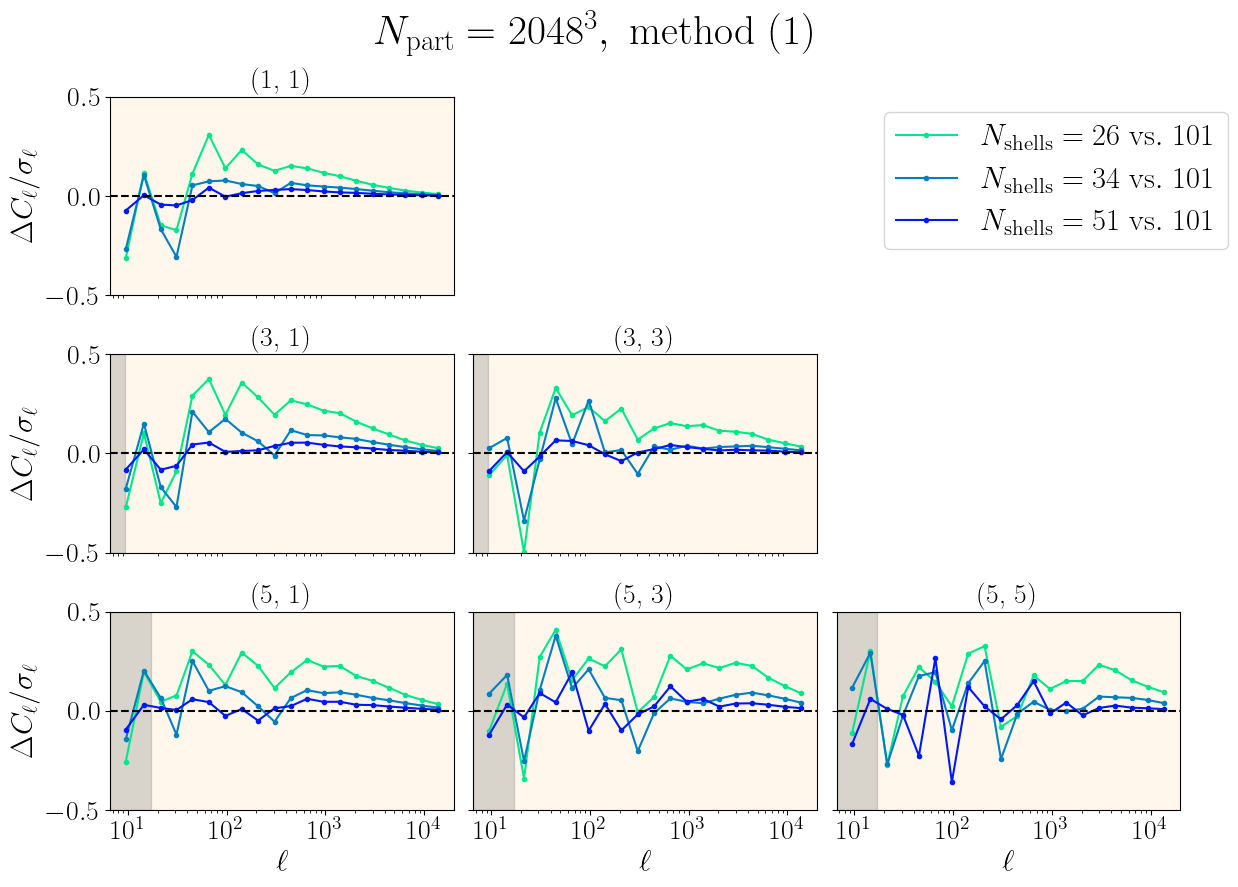

In [12]:
map_list = np.arange(0, 5)
map_list = [0, 2, 4]

shotnoise = None

from plots_methods import plot_Cls_kappa

# Plot 4
plot_Cls_kappa(4, map_list, Cls_dict, Cls_th, ell_min_dict, list_plot, shotnoise, ylim=[-0.5, 0.5])


In [13]:
list_chi2 = [
    (N_part_a, "avg", "avg", 26, extra_info),
    (N_part_a, "avg", "avg", 34, extra_info),
    (N_part_a, "avg", "avg", 51, extra_info),
    (N_part_a, "avg", "avg", 101, extra_info),
]

Cls_dict_chi2 = {key: Cls_dict[key] for key in list_chi2 if key in Cls_dict}

for key, value in Cls_dict_chi2.items():
    value["concatenated"] = np.concatenate([
        value[f"({j}, {i})"][:, 1][ell >= max(ell_min_dict[i], ell_min_dict[j])]
        for i in range(len(lensing.nzs))
        for j in range(i, len(lensing.nzs))
    ])

Cls_th_concatenated = np.concatenate([
    Cls_th[1][(j, i)][ell >= max(ell_min_dict[i], ell_min_dict[j])]
    for i in range(len(lensing.nzs))
    for j in range(i, len(lensing.nzs))
])

sigmals_th_concatenated = np.concatenate([
    Cls_th[2][(j, i)][ell >= max(ell_min_dict[i], ell_min_dict[j])]
    for i in range(len(lensing.nzs))
    for j in range(i, len(lensing.nzs))
])

included_indices = []
offset = 0

for i in range(len(lensing.nzs)):
    for j in range(i, len(lensing.nzs)):
        mask = ell >= max(ell_min_dict[i], ell_min_dict[j])
        n_kept = np.sum(mask)
        included_indices.extend(np.arange(offset, offset + len(mask))[mask])
        offset += len(mask)

cov_cut = Cls_th[4][np.ix_(included_indices, included_indices)]

print("This has to be zero:")
print((sigmals_th_concatenated - np.sqrt(np.diag(cov_cut))).max())

print("")
print("chi2 vs theory")

for key, value in Cls_dict_chi2.items():
    delta = value["concatenated"] - Cls_th_concatenated
    chi2 = delta @ np.linalg.inv(cov_cut) @ delta
    print([key, round(chi2, 2)])

print("")
print("Pairwise chi2")

for key_1, value_1 in Cls_dict_chi2.items():
    for key_2, value_2 in Cls_dict_chi2.items():
        if int(key_2[3]) > int(key_1[3]) and int(key_2[3]) == 101:
            delta = value_1["concatenated"] - value_2["concatenated"]
            chi2 = delta @ np.linalg.inv(cov_cut) @ delta
            print([key_1, key_2, round(chi2, 2)])


This has to be zero:
0.0

chi2 vs theory
[(2048, 'avg', 'avg', 26, 'method\\ (1)'), 11.55]
[(2048, 'avg', 'avg', 34, 'method\\ (1)'), 10.61]
[(2048, 'avg', 'avg', 51, 'method\\ (1)'), 10.99]
[(2048, 'avg', 'avg', 101, 'method\\ (1)'), 12.73]

Pairwise chi2
[(2048, 'avg', 'avg', 26, 'method\\ (1)'), (2048, 'avg', 'avg', 101, 'method\\ (1)'), 5.85]
[(2048, 'avg', 'avg', 34, 'method\\ (1)'), (2048, 'avg', 'avg', 101, 'method\\ (1)'), 2.76]
[(2048, 'avg', 'avg', 51, 'method\\ (1)'), (2048, 'avg', 'avg', 101, 'method\\ (1)'), 1.21]


In [14]:
list_plot = [
    (N_part_b, "avg", "avg", 26, extra_info),
    (N_part_b, "avg", "avg", 34, extra_info),
    (N_part_b, "avg", "avg", 51, extra_info),
    (N_part_b, "avg", "avg", 101, extra_info),
]


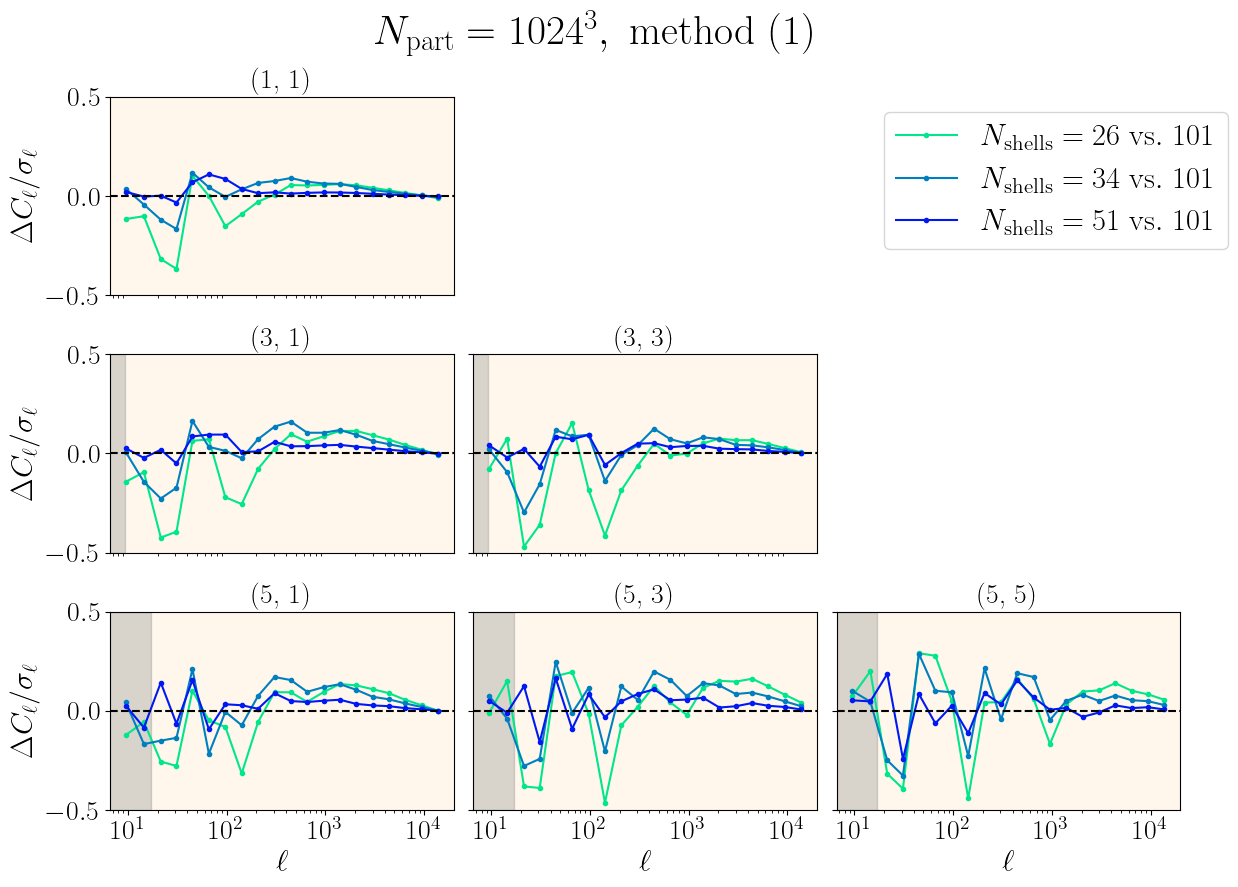

In [15]:
map_list = np.arange(0, 5)
map_list = [0, 2, 4]

shotnoise = None

from plots_methods import plot_Cls_kappa

# Plot 4
plot_Cls_kappa(4, map_list, Cls_dict, Cls_th, ell_min_dict, list_plot, shotnoise, filename_extra="1024", ylim=[-0.5, 0.5])


In [16]:
list_chi2 = [
    (N_part_b, "avg", "avg", 26, extra_info),
    (N_part_b, "avg", "avg", 34, extra_info),
    (N_part_b, "avg", "avg", 51, extra_info),
    (N_part_b, "avg", "avg", 101, extra_info),
]

Cls_dict_chi2 = {key: Cls_dict[key] for key in list_chi2 if key in Cls_dict}

for key, value in Cls_dict_chi2.items():
    value["concatenated"] = np.concatenate([
        value[f"({j}, {i})"][:, 1][ell >= max(ell_min_dict[i], ell_min_dict[j])]
        for i in range(len(lensing.nzs))
        for j in range(i, len(lensing.nzs))
    ])

Cls_th_concatenated = np.concatenate([
    Cls_th[1][(j, i)][ell >= max(ell_min_dict[i], ell_min_dict[j])]
    for i in range(len(lensing.nzs))
    for j in range(i, len(lensing.nzs))
])

sigmals_th_concatenated = np.concatenate([
    Cls_th[2][(j, i)][ell >= max(ell_min_dict[i], ell_min_dict[j])]
    for i in range(len(lensing.nzs))
    for j in range(i, len(lensing.nzs))
])

included_indices = []
offset = 0

for i in range(len(lensing.nzs)):
    for j in range(i, len(lensing.nzs)):
        mask = ell >= max(ell_min_dict[i], ell_min_dict[j])
        n_kept = np.sum(mask)
        included_indices.extend(np.arange(offset, offset + len(mask))[mask])
        offset += len(mask)

cov_cut = Cls_th[4][np.ix_(included_indices, included_indices)]

print("This has to be zero:")
print((sigmals_th_concatenated - np.sqrt(np.diag(cov_cut))).max())

print("")
print("chi2 vs theory")

for key, value in Cls_dict_chi2.items():
    delta = value["concatenated"] - Cls_th_concatenated
    chi2 = delta @ np.linalg.inv(cov_cut) @ delta
    print([key, round(chi2, 2)])

print("")
print("Pairwise chi2")

for key_1, value_1 in Cls_dict_chi2.items():
    for key_2, value_2 in Cls_dict_chi2.items():
        if int(key_2[3]) > int(key_1[3]) and int(key_2[3]) == 101:
            delta = value_1["concatenated"] - value_2["concatenated"]
            chi2 = delta @ np.linalg.inv(cov_cut) @ delta
            print([len(delta), key_1, key_2, round(chi2, 2)])



This has to be zero:
0.0

chi2 vs theory
[(1024, 'avg', 'avg', 26, 'method\\ (1)'), 17.95]
[(1024, 'avg', 'avg', 34, 'method\\ (1)'), 16.33]
[(1024, 'avg', 'avg', 51, 'method\\ (1)'), 17.19]
[(1024, 'avg', 'avg', 101, 'method\\ (1)'), 18.2]

Pairwise chi2
[286, (1024, 'avg', 'avg', 26, 'method\\ (1)'), (1024, 'avg', 'avg', 101, 'method\\ (1)'), 2.84]
[286, (1024, 'avg', 'avg', 34, 'method\\ (1)'), (1024, 'avg', 'avg', 101, 'method\\ (1)'), 1.82]
[286, (1024, 'avg', 'avg', 51, 'method\\ (1)'), (1024, 'avg', 'avg', 101, 'method\\ (1)'), 0.69]


In [17]:
list_plot = [
    (N_part_a, "avg", "avg", 101, extra_info),
    (N_part_b, "avg", "avg", 101, extra_info),
]


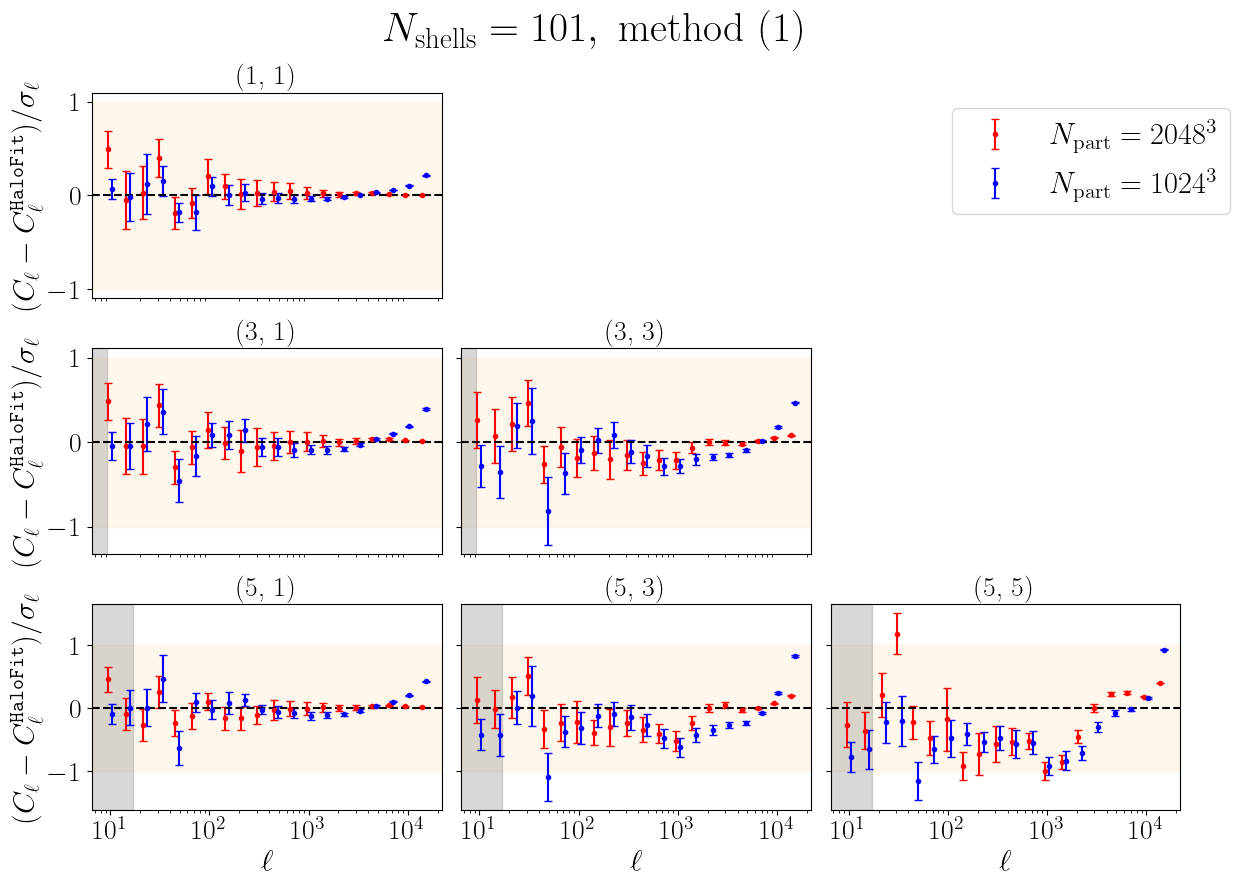

In [18]:
map_list = np.arange(0, 5)
map_list = [0, 2, 4]

from plots_methods import plot_Cls_kappa

# Plot 3
plot_Cls_kappa(10, map_list, Cls_dict, Cls_th, ell_min_dict, list_plot, filename_extra="2048_vs_1024", ylabel=r"$(C_\ell-C_\ell^{\tt HaloFit})/\sigma_\ell$")
